# 🦅 Choosing the Right Pretraining Dataset for Kestrel

Every strong small language model starts long before `loss.backward()` ever runs—it starts with what you feed it.

We're building **Kestrel**, a **350M–700M parameter** decoder-only LLM aiming to outperform OpenAI's 1.5B **GPT-2 XL** at less than half its parameter count. To keep our training loop clean, debuggable, and reproducible, we're making one deliberate engineering bet:

> **One dataset, start to finish.** No fragile multi-stage curriculum juggling five buckets—just pick the single strongest open pretraining corpus and train cleanly on it.

Just as importantly, this audit stays **strictly blind to our held-out evaluation benchmarks**. Peeking at test sets to choose a training corpus is subtle benchmark overfitting—and as published scaling studies show, raw word overlap doesn't even predict actual pretraining performance reliably.

### Notebook Roadmap
We stream an equal, randomly sampled slice (~3.5M GPT-2 tokens) from four modern open corpora—**FineWeb-Edu**, **DCLM-Baseline 1.0**, **Nemotron-ClimbMix**, and **FinePDFs-Edu**—plus **OpenWebText** as a control representing GPT-2's 2019 world, and walk through five crisp stages:

1. **Environment Setup & Config** — Bootstrap packages, shared `kestrel.utils`, and reproducible sampling settings.
2. **Multi-Shard Random Streaming** — Pull unbiased ~3.5M-token slices from 8 random shards per corpus without melting local disk.
3. **Exploratory Data Analysis & Spot-Checks** — Inspect document lengths, formatting signals, TF-IDF fingerprints, and real random excerpts.
4. **BERT Semantic Topic Map** — Cluster `2,500` docs in `all-MiniLM-L6-v2` space, label broad subjects via `flan-t5-small`, and view a full-width composition heatmap.
5. **Summary & Published Scaling Evidence** — Lay out raw corpus metrics side by side (no arbitrary weights) alongside controlled scaling results from **CLIMB**, **DCLM**, and **FineWeb-Edu** to guide our final decision in `README.md`.


---
## 1. Environment Setup & Configuration

All audit logic lives directly inside this notebook for readability, while reusable environment and tokenization helpers (`kestrel.utils`) are imported from [**github.com/MohammedKamalAlsyd/kestrel**](https://github.com/MohammedKamalAlsyd/kestrel).

💡 **Running on Kaggle?** Make sure **Internet** is turned ON in the right-hand sidebar. Enabling a **T4 GPU** is optional, but it drops the BERT embedding step from ~1 minute down to ~10 seconds.


In [4]:
# === 1.1 Dependency & Repository Bootstrap ===
# Installs any missing audit packages and ensures `src/kestrel/utils` is importable
# both locally and in a fresh Kaggle notebook session.

import shutil
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/MohammedKamalAlsyd/kestrel.git"
_BOOTSTRAP_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()

# Quietly install only packages missing from the current environment
REQUIRED_PACKAGES = [
    ("datasets", "datasets>=3.0.0"),
    ("tiktoken", "tiktoken>=0.7.0"),
    ("zstandard", "zstandard>=0.22"),
    ("seaborn", "seaborn>=0.13"),
    ("sklearn", "scikit-learn>=1.4"),
    ("sentence_transformers", "sentence-transformers>=3.0"),
    ("transformers", "transformers>=4.40"),
]
missing_specs = []
for module_name, pip_spec in REQUIRED_PACKAGES:
    try:
        __import__(module_name)
    except ImportError:
        missing_specs.append(pip_spec)

if missing_specs:
    print("Installing missing packages:", ", ".join(missing_specs))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_specs])

# Locate an existing local checkout first; shallow-clone on Kaggle if needed
REPO_ROOT = None
for candidate_root in [
    Path.cwd(),
    Path.cwd().parent,
    Path("/kaggle/input/kestrel"),
    _BOOTSTRAP_DIR / "kestrel",
]:
    if (candidate_root / "src" / "kestrel" / "utils" / "notebook.py").exists():
        REPO_ROOT = candidate_root.resolve()
        break

if REPO_ROOT is None:
    clone_dir = _BOOTSTRAP_DIR / "kestrel"
    if (clone_dir / ".git").exists():
        subprocess.check_call(["git", "-C", str(clone_dir), "pull", "--ff-only"])
    else:
        if clone_dir.exists() and any(clone_dir.iterdir()):
            shutil.rmtree(clone_dir, ignore_errors=True)
        res = subprocess.run(
            ["git", "clone", "--depth", "1", REPO_URL, str(clone_dir)],
            capture_output=True,
            text=True,
        )
        if res.returncode != 0:
            raise RuntimeError(
                f"git clone failed (exit {res.returncode}). "
                f"Make sure Kaggle Internet is ON.\nstderr: {res.stderr.strip()}"
            )
    REPO_ROOT = clone_dir.resolve()

src_path = str((REPO_ROOT / "src").resolve())
if src_path not in sys.path:
    sys.path.insert(0, src_path)

print(f"[OK] Kestrel repository ready at: {REPO_ROOT}")


[OK] Kestrel repository ready at: /kaggle/working/kestrel


In [5]:
# === 1.2 Core Imports, Working Paths & Experiment Configuration ===
# Centralizes all reproducible audit parameters so tweaking sample budgets
# or topic-modeling hyperparameters happens in one place.

import gc
import json
import math
import random
import re
import time
from dataclasses import dataclass, field
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from IPython.display import display

from kestrel.utils.notebook import configure_hf_cache, get_work_dir, is_kaggle
from kestrel.utils.text import count_gpt2_tokens, get_gpt2_tokenizer, normalize_words

# Workspace directories (all outputs stay inside working dir / Kaggle-safe bounds)
WORK_DIR = get_work_dir()
SAMPLES_DIR = WORK_DIR / "samples"
FIGURES_DIR = SAMPLES_DIR / "figures"
CACHE_DIR = WORK_DIR / ".hf_cache"
SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Configure plotting theme, low-disk HF cache, and compute device
sns.set_theme(style="whitegrid", context="notebook")
configure_hf_cache(CACHE_DIR)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# --- Sampling Configuration ---
TARGET_TOKENS = 3_500_000     # Token budget per corpus (GPT-2 BPE tokens)
MAX_DOCS = 5_000              # Cap doc count so short-doc corpora stay fast
RANDOM_SAMPLE = True          # Multi-shard random sampling avoids shard-0 prefix bias
NUM_SHARDS_TO_SAMPLE = 8      # Sample evenly across 8 distinct remote shards
SHUFFLE_BUFFER_SIZE = 2_000   # Per-shard streaming shuffle buffer
SEED = 42                     # Global seed for deterministic sampling & clustering
FORCE_REFRESH = False         # Set True to bypass cached JSONL slices in samples/

# --- BERT Topic Modeling Configuration ---
BERT_EMBED_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
TOPIC_NAMER_MODEL = "google/flan-t5-small"
N_TOPICS = 12
TOPIC_DOCS_PER_DATASET = 500

print(f"Environment : {'Kaggle' if is_kaggle() else 'Local'} | Device: {DEVICE.upper()}")
print(f"Outputs dir : {SAMPLES_DIR}")


Environment : Kaggle | Device: CUDA
Outputs dir : /kaggle/working/samples


---
## 2. Sampling Terabytes Without Melting Our Disk

Full web corpora like `DCLM-Baseline` (~3.8T tokens) or `FineWeb-Edu` (~1.3T tokens) would instantly blow past a 20 GB Kaggle disk. At the same time, taking the lazy shortcut—grabbing just the *first* 5,000 rows of shard `00000`—is a classic trap. Many web datasets are grouped by crawl dump, date, or URL host, so the opening slice can look wildly unrepresentative.

Our streaming sampler solves both problems cleanly:
* **No prefix bias:** Jumps into **`8` randomly chosen remote shards** across each corpus (`ds.n_shards`) and shuffles rows inside every shard (`buffer_size=2,000`).
* **Equal token budgets:** Counts **GPT-2 BPE tokens** (`tiktoken`) on the fly, stopping at **`3.5M` tokens** or **`5,000` docs** (whichever hits first) and caching a compact ~15 MB JSONL file under `samples/`.


In [6]:
# === 2.1 Candidate Pretraining Corpus Registry ===
# Each entry pairs a primary Parquet-native Hugging Face repo with resilient
# fallbacks so streaming stays reliable across datasets>=3.x/4.x environments.

from datasets import load_dataset


@dataclass(frozen=True)
class DatasetSpec:
    """Metadata and streaming endpoints for one candidate pretraining corpus."""

    key: str
    display_name: str
    repo_id: str
    config: str | None = None
    split: str = "train"
    text_field: str = "text"
    license: str = "Unknown"
    load_kwargs: dict[str, Any] = field(default_factory=dict)
    fallbacks: tuple[dict[str, Any], ...] = ()


CANDIDATE_DATASETS: dict[str, DatasetSpec] = {
    "fineweb_edu": DatasetSpec(
        key="fineweb_edu",
        display_name="FineWeb-Edu (10BT)",
        repo_id="HuggingFaceFW/fineweb-edu",
        config="sample-10BT",
        license="ODC-By v1.0",
    ),
    "dclm_baseline": DatasetSpec(
        key="dclm_baseline",
        display_name="DCLM-Baseline 1.0",
        repo_id="mlfoundations/dclm-baseline-1.0-parquet",
        license="CC-BY-4.0",
        fallbacks=(
            {
                "repo_id": "json",
                "config": None,
                "split": "train",
                "load_kwargs": {
                    "data_files": "hf://datasets/mlfoundations/dclm-baseline-1.0/**/*_processed.jsonl.zst"
                },
            },
        ),
    ),
    "climbmix": DatasetSpec(
        key="climbmix",
        display_name="Nemotron-ClimbMix (400B)",
        repo_id="karpathy/climbmix-400b-shuffle",
        license="CC-BY-NC-4.0 (upstream NVIDIA; MIT mirror)",
        fallbacks=(
            {"repo_id": "OptimalScale/ClimbMix", "config": None, "split": "train", "load_kwargs": {}},
        ),
    ),
    "finepdfs_edu": DatasetSpec(
        key="finepdfs_edu",
        display_name="FinePDFs-Edu (eng_Latn)",
        repo_id="HuggingFaceFW/finepdfs-edu",
        config="eng_Latn",
        license="ODC-By v1.0",
        fallbacks=(
            {"repo_id": "HuggingFaceFW/finepdfs", "config": "eng_Latn", "split": "train", "load_kwargs": {}},
        ),
    ),
    "openwebtext": DatasetSpec(
        key="openwebtext",
        display_name="OpenWebText (GPT-2 Control)",
        repo_id="Skylion007/openwebtext",
        license="Public Domain / CC0",
        fallbacks=(
            {
                "repo_id": "parquet",
                "config": None,
                "split": "train",
                "load_kwargs": {
                    "data_files": "hf://datasets/Skylion007/openwebtext@refs/convert/parquet/plain_text/train/*.parquet"
                },
            },
            {"repo_id": "stas/openwebtext-10k", "config": None, "split": "train", "load_kwargs": {}},
        ),
    ),
}

print(f"Registered {len(CANDIDATE_DATASETS)} corpora:", ", ".join(s.display_name for s in CANDIDATE_DATASETS.values()))


Registered 5 corpora: FineWeb-Edu (10BT), DCLM-Baseline 1.0, Nemotron-ClimbMix (400B), FinePDFs-Edu (eng_Latn), OpenWebText (GPT-2 Control)


In [7]:
# === 2.2 Multi-Shard Random Streaming & JSONL Caching Helpers ===
# Streams equal token slices across randomly selected remote shards and writes
# atomically via a `.tmp` file so interrupted runs never leave corrupt caches.


def load_jsonl_slice(path: Path) -> list[dict[str, Any]]:
    """Load a cached JSONL slice from disk."""
    with path.open("r", encoding="utf-8") as fh:
        return [json.loads(line) for line in fh if line.strip()]


def _open_hf_iterable(spec: DatasetSpec) -> Any:
    """Open the first working streaming endpoint from a DatasetSpec and its fallbacks."""
    attempts = [
        {"repo_id": spec.repo_id, "config": spec.config, "split": spec.split, "load_kwargs": dict(spec.load_kwargs)},
        *[dict(fb) for fb in spec.fallbacks],
    ]
    last_exc = None
    for attempt in attempts:
        kwargs = {"split": attempt.get("split", spec.split), "streaming": True, **attempt.get("load_kwargs", {})}
        try:
            cfg = attempt.get("config")
            ds = (
                load_dataset(attempt["repo_id"], cfg, **kwargs)
                if cfg is not None
                else load_dataset(attempt["repo_id"], **kwargs)
            )
            # Probe 1 row immediately so broken/gated repos trigger fallback right away
            _ = next(iter(ds))
            return ds
        except Exception as exc:
            last_exc = exc
    raise RuntimeError(f"Failed to stream '{spec.key}': {last_exc}") from last_exc


def stream_matched_slice(
    spec: DatasetSpec,
    cache_path: Path,
    target_tokens: int = TARGET_TOKENS,
    max_docs: int = MAX_DOCS,
    min_chars: int = 64,
    force_refresh: bool = FORCE_REFRESH,
    random_sample: bool = RANDOM_SAMPLE,
    num_shards_to_sample: int = NUM_SHARDS_TO_SAMPLE,
    shuffle_buffer_size: int = SHUFFLE_BUFFER_SIZE,
    seed: int = SEED,
) -> list[dict[str, Any]]:
    """Stream a token-matched, shard-randomized slice and cache it locally as JSONL."""
    if cache_path.exists() and not force_refresh:
        return load_jsonl_slice(cache_path)

    enc = get_gpt2_tokenizer()
    ds = _open_hf_iterable(spec)

    # Distribute sampling evenly across `num_shards_to_sample` randomly chosen shards
    n_shards = int(getattr(ds, "n_shards", 1) or 1)
    if random_sample and n_shards > 1 and hasattr(ds, "shard"):
        k = min(max(1, num_shards_to_sample), n_shards)
        chosen_shards = random.Random(seed).sample(range(n_shards), k)
        shard_iters = []
        for shard_idx in chosen_shards:
            shard_ds = ds.shard(num_shards=n_shards, index=shard_idx)
            if shuffle_buffer_size > 1 and hasattr(shard_ds, "shuffle"):
                shard_ds = shard_ds.shuffle(seed=seed + shard_idx, buffer_size=shuffle_buffer_size)
            shard_iters.append(iter(shard_ds))
    elif random_sample and shuffle_buffer_size > 1 and hasattr(ds, "shuffle"):
        shard_iters = [iter(ds.shuffle(seed=seed, buffer_size=shuffle_buffer_size))]
    else:
        shard_iters = [iter(ds)]

    records: list[dict[str, Any]] = []
    total_tokens = 0
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    tmp_file = cache_path.with_suffix(".jsonl.tmp")

    with tmp_file.open("w", encoding="utf-8") as fh:
        for pos, row_iter in enumerate(shard_iters):
            rem_shards = len(shard_iters) - pos
            rem_tokens = max(0, target_tokens - total_tokens)
            rem_docs = max(0, max_docs - len(records))
            if rem_tokens == 0 or rem_docs == 0:
                break

            # Dynamically rebalance remaining budget across remaining shards
            tok_quota = math.ceil(rem_tokens / rem_shards)
            doc_quota = math.ceil(rem_docs / rem_shards)
            shard_tokens = 0
            shard_docs = 0

            for row in row_iter:
                raw = row.get(spec.text_field)
                if not isinstance(raw, str):
                    continue
                text = raw.strip()
                if len(text) < min_chars:
                    continue
                n_tok = count_gpt2_tokens(text, enc)
                if n_tok == 0:
                    continue

                rec = {"text": text, "n_tokens": n_tok}
                records.append(rec)
                fh.write(json.dumps(rec, ensure_ascii=False) + "\n")
                total_tokens += n_tok
                shard_tokens += n_tok
                shard_docs += 1

                if (
                    len(records) >= max_docs
                    or total_tokens >= target_tokens
                    or shard_docs >= doc_quota
                    or shard_tokens >= tok_quota
                ):
                    break

    tmp_file.replace(cache_path)
    return records


In [8]:
# === 2.3 Execute Multi-Shard Streaming & Inspect Slice Inventory ===
# Re-running this cell reuses cached ~15 MB JSONL files in `samples/` unless FORCE_REFRESH=True.

candidate_slices: dict[str, list[dict[str, Any]]] = {}
stream_summary_rows: list[dict[str, Any]] = []

print("=== Streaming Multi-Shard Random Slices ===")
for key, spec in CANDIDATE_DATASETS.items():
    cache_file = SAMPLES_DIR / f"{key}.jsonl"
    t0 = time.time()
    try:
        recs = stream_matched_slice(spec, cache_file)
        candidate_slices[key] = recs
        n_tok = sum(r["n_tokens"] for r in recs)
        mb = cache_file.stat().st_size / (1024 * 1024)
        print(
            f"[OK]   {spec.display_name:<28s} | {len(recs):>5,d} docs "
            f"| {n_tok:>9,d} tok | {mb:>5.1f} MB | {time.time() - t0:>5.1f}s"
        )
        stream_summary_rows.append({
            "Dataset": spec.display_name,
            "License": spec.license,
            "Docs": len(recs),
            "GPT-2 Tokens": n_tok,
            "Mean Tok/Doc": round(n_tok / max(len(recs), 1), 1),
            "JSONL (MB)": round(mb, 2),
        })
    except Exception as exc:
        print(f"[SKIP] {spec.display_name}: {exc}")

# Shared ordered keys, human labels, and consistent plot colors for downstream cells
ds_keys = list(candidate_slices.keys())
ds_labels = {k: CANDIDATE_DATASETS[k].display_name for k in ds_keys}
palette = dict(zip(ds_keys, sns.color_palette("tab10", n_colors=max(len(ds_keys), 1))))

display(pd.DataFrame(stream_summary_rows))


=== Streaming Multi-Shard Random Slices ===
[OK]   FineWeb-Edu (10BT)           | 3,319 docs | 3,501,102 tok |  15.7 MB |   0.1s
[OK]   DCLM-Baseline 1.0            | 2,734 docs | 3,500,699 tok |  14.6 MB |   0.1s
[OK]   Nemotron-ClimbMix (400B)     | 5,000 docs | 3,160,216 tok |  14.2 MB |   0.1s
[OK]   FinePDFs-Edu (eng_Latn)      | 1,080 docs | 3,500,022 tok |  14.8 MB |   0.1s
[OK]   OpenWebText (GPT-2 Control)  | 3,160 docs | 3,500,186 tok |  15.0 MB |   0.1s


,Dataset,License,Docs,GPT-2 Tokens,Mean Tok/Doc,JSONL (MB)
0,FineWeb-Edu (10BT),ODC-By v1.0,3319,3501102,1054.9,15.73
1,DCLM-Baseline 1.0,CC-BY-4.0,2734,3500699,1280.4,14.61
2,Nemotron-ClimbMix (400B),CC-BY-NC-4.0 (upstream NVIDIA; MIT mirror),5000,3160216,632.0,14.24
3,FinePDFs-Edu (eng_Latn),ODC-By v1.0,1080,3500022,3240.8,14.79
4,OpenWebText (GPT-2 Control),Public Domain / CC0,3160,3500186,1107.7,14.96


---
## 3. First Rule of Data Engineering: Actually Read It

Before letting any embedding model speak, let's do the simplest—and highest-ROI—thing in ML: **open the box and look inside.**

In the three quick cells below, we compute document-length and formatting profiles, plot them side by side, and inspect both signature TF-IDF words and raw random excerpts from each corpus.


In [9]:
# === 3.1 Compute Document Length & Character-Level Formatting Profiles ===
# Quantifies token-length quantiles (Median/Mean/P90/P99) and structural cues
# (digits, uppercase, punctuation/symbols, and newline density) per dataset.

SENT_SPLIT_RE = re.compile(r"[.!?]+")

eda_rows: list[dict[str, Any]] = []
length_plot_rows: list[dict[str, Any]] = []

for dkey in ds_keys:
    recs = candidate_slices[dkey]
    tok_lens = np.array([r["n_tokens"] for r in recs], dtype=np.float64)
    texts = [r["text"] for r in recs]

    word_lens, sent_lens = [], []
    digit_pcts, upper_pcts, sym_pcts, nl_per_1k = [], [], [], []

    for txt in texts:
        n_chars = max(len(txt), 1)
        digit_pcts.append(100.0 * sum(c.isdigit() for c in txt) / n_chars)
        upper_pcts.append(100.0 * sum(c.isupper() for c in txt) / n_chars)
        sym_pcts.append(100.0 * sum((not c.isalnum()) and (not c.isspace()) for c in txt) / n_chars)
        nl_per_1k.append(1000.0 * txt.count("\n") / n_chars)

        words = normalize_words(txt)
        sents = [s for s in SENT_SPLIT_RE.split(txt) if s.strip()]
        if words:
            word_lens.append(float(np.mean([len(w) for w in words])))
            sent_lens.append(len(words) / max(len(sents), 1))

    eda_rows.append({
        "Dataset": ds_labels[dkey],
        "Docs": len(recs),
        "Median Tok/Doc": round(float(np.median(tok_lens)), 1),
        "Mean Tok/Doc": round(float(np.mean(tok_lens)), 1),
        "P90 Tok/Doc": round(float(np.percentile(tok_lens, 90)), 1),
        "P99 Tok/Doc": round(float(np.percentile(tok_lens, 99)), 1),
        "Mean Word Len": round(float(np.mean(word_lens)), 2),
        "Words / Sent": round(float(np.mean(sent_lens)), 1),
        "Digits (%)": round(float(np.mean(digit_pcts)), 2),
        "Uppercase (%)": round(float(np.mean(upper_pcts)), 2),
        "Symbols (%)": round(float(np.mean(sym_pcts)), 2),
        "Newlines / 1k Chars": round(float(np.mean(nl_per_1k)), 2),
    })
    for t_len in tok_lens:
        length_plot_rows.append({"Dataset": ds_labels[dkey], "Tokens": t_len})

eda_df = pd.DataFrame(eda_rows)
display(eda_df)


,Dataset,Docs,Median Tok/Doc,Mean Tok/Doc,P90 Tok/Doc,P99 Tok/Doc,Mean Word Len,Words / Sent,Digits (%),Uppercase (%),Symbols (%),Newlines / 1k Chars
0,FineWeb-Edu (10BT),3319,644.0,1054.9,2086.6,7930.6,4.95,18.9,0.86,2.88,2.83,4.53
1,DCLM-Baseline 1.0,2734,674.5,1280.4,2503.6,12961.3,4.64,18.2,0.96,3.22,3.22,12.26
2,Nemotron-ClimbMix (400B),5000,541.0,632.0,1006.2,3871.3,4.85,18.5,0.74,2.86,2.82,7.57
3,FinePDFs-Edu (eng_Latn),1080,1356.0,3240.8,7473.8,30095.2,4.99,18.8,1.60,4.44,4.51,17.43
4,OpenWebText (GPT-2 Control),3160,724.5,1107.7,2099.5,6965.8,4.69,19.5,0.94,3.57,3.13,8.87


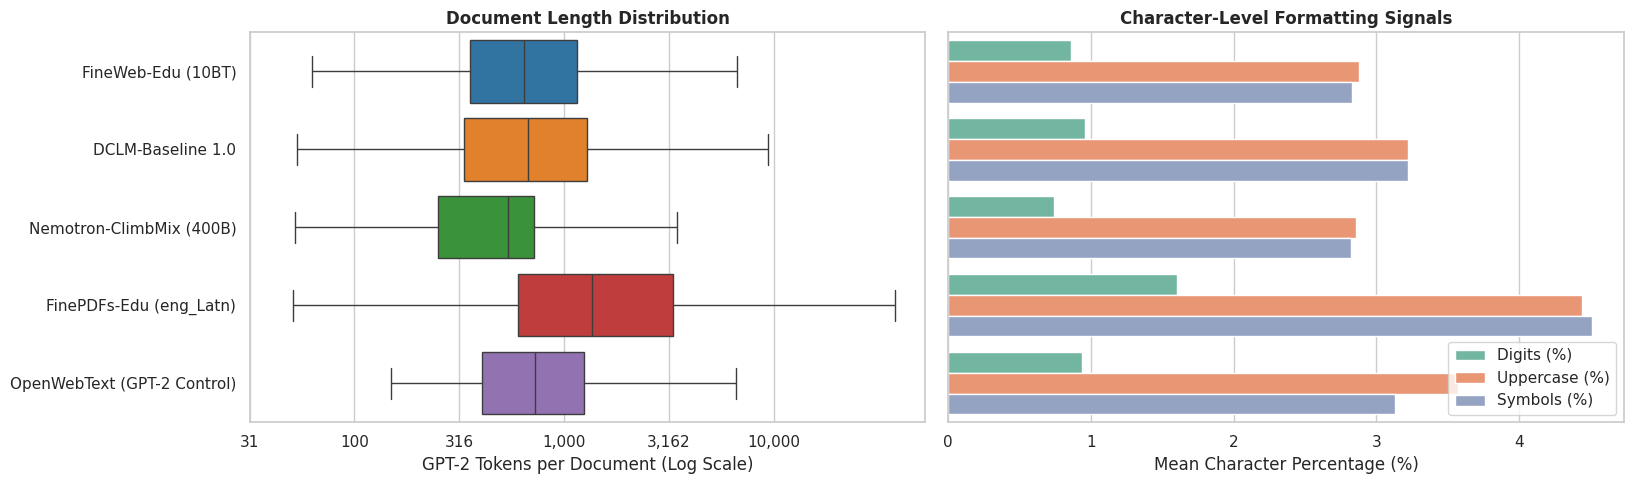

In [10]:
# === 3.2 Visualize Length Distributions & Character Formatting Signals ===
# Isolated plotting cell so figure styling can be iterated without recomputing stats.

fig, (ax_len, ax_struct) = plt.subplots(1, 2, figsize=(16.5, 5.0))

# Left panel: log10 document token-length distribution (outliers hidden for clarity)
len_df = pd.DataFrame(length_plot_rows)
len_df["Log10 Tokens"] = np.log10(np.clip(len_df["Tokens"], 1, None))
sns.boxplot(
    data=len_df,
    y="Dataset",
    x="Log10 Tokens",
    hue="Dataset",
    legend=False,
    palette=[palette[k] for k in ds_keys],
    ax=ax_len,
    showfliers=False,
)
tick_vals = [1.5, 2.0, 2.5, 3.0, 3.5, 4.0]
ax_len.set_xticks(tick_vals)
ax_len.set_xticklabels([f"{int(10**v):,}" for v in tick_vals])
ax_len.set_xlabel("GPT-2 Tokens per Document (Log Scale)")
ax_len.set_ylabel("")
ax_len.set_title("Document Length Distribution", fontsize=12, fontweight="bold")

# Right panel: structural character ratios (high digits/symbols often indicate tables, PDFs, or markup)
struct_melt = eda_df.melt(
    id_vars=["Dataset"],
    value_vars=["Digits (%)", "Uppercase (%)", "Symbols (%)"],
    var_name="Signal",
    value_name="Percent",
)
sns.barplot(data=struct_melt, y="Dataset", x="Percent", hue="Signal", ax=ax_struct, palette="Set2")
ax_struct.set_ylabel("")
ax_struct.set_yticklabels([])
ax_struct.set_xlabel("Mean Character Percentage (%)")
ax_struct.set_title("Character-Level Formatting Signals", fontsize=12, fontweight="bold")
ax_struct.legend(loc="lower right")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_eda_length_and_structure.png", dpi=150, bbox_inches="tight")
plt.show()


In [11]:
# === 3.3 Signature TF-IDF Terms & Random Document Spot-Check ===
# Treats each corpus as a mega-document (`max_df=0.85`) to highlight vocabulary
# uniquely enriched in one dataset, then prints 1 random raw excerpt per corpus.

from sklearn.feature_extraction.text import TfidfVectorizer

# Cap per-doc snippet length so long PDFs don't dominate TF-IDF term counts
corpus_docs = [" ".join(r["text"][:1500] for r in candidate_slices[k][:600]) for k in ds_keys]
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=15_000,
    min_df=1,
    max_df=0.85,
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
)
X_tfidf = tfidf.fit_transform(corpus_docs)
vocab_terms = np.array(tfidf.get_feature_names_out())

print("=== Signature TF-IDF Terms per Dataset ===")
for idx, dkey in enumerate(ds_keys):
    top_terms = vocab_terms[np.argsort(X_tfidf[idx].toarray().ravel())[::-1][:10]]
    print(f"  • {ds_labels[dkey]:<28s}: {', '.join(top_terms)}")

# Tip: change SEED below to inspect additional random samples without re-running earlier cells
print("\n=== Random Document Spot-Check ===")
rng_spot = random.Random(SEED)
for dkey in ds_keys:
    sample_rec = rng_spot.choice(candidate_slices[dkey])
    snippet = re.sub(r"\s+", " ", sample_rec["text"])[:280]
    print(f"\n[{ds_labels[dkey]} | {sample_rec['n_tokens']:,} tokens]\n  \"{snippet}...\"")


=== Signature TF-IDF Terms per Dataset ===
  • FineWeb-Edu (10BT)          : asin, voltage, sql, radios, vitamin, sepsis, bergen, mime, lake, classroom
  • DCLM-Baseline 1.0           : golf, album, twitter, blogging, arbitration, blur, police, guy, blogger, payment
  • Nemotron-ClimbMix (400B)    : zinc, flowers, photography, printer, metal, organic, marine, grapefruit, surf, meat
  • FinePDFs-Edu (eng_Latn)     : curriculum, christ, fruit, lastname, firstname, maggie, pupils, asbestosis, stormwater, classroom
  • OpenWebText (GPT-2 Control) : police, clinton, twitter, bitcoin, fbi, officer, obama, getty, reuters, democrats

=== Random Document Spot-Check ===

[FineWeb-Edu (10BT) | 334 tokens]
  "The symptoms related to overflow incontinence are typically continuous loss of urine or urinary leakage connected to movement. It may occur in both men and women. In men, an enlarged prostate causes the problem. The prostate gland is normally the size of a chestnut and only found..."

[DCLM-B

### What Jumped Straight Off the Page

Even before touching embeddings, five random excerpts and a couple of length charts already reveal how differently these corpora behave:

* **`FinePDFs-Edu` lives on another planet structurally:** It burned through our entire 3.5M-token budget in just `1,080` documents (`3,241` tokens/doc mean, `P99 = 30,095`), carrying nearly **double the digits (`1.60%`)** and **`17.4` newlines per 1k chars** from tables, headers, and bullet lists. Even more revealing—our very first random spot-check landed directly on a classic SEO ebook-spam PDF (*"Ems 2014 June Exam Grade 9 Paper Yeah, reviewing a ebook... could build up your near contacts listings"*). That single excerpt justifies spot-checking all by itself.
* **`FineWeb-Edu` is the cleanest paragraph writer in the room:** Lowest newline clutter (`4.53 / 1k chars`), steady ~1,055-token articles, and our random draw was a crisp, textbook-grade medical explanation.
* **`DCLM-Baseline 1.0` reads like natural, well-edited web journalism:** Generous document lengths (`1,280` tok/doc mean, `P99 = 12,961`), and our random sample (*"How Monster Jam Works..."*) flows smoothly—classic everyday English that builds strong fluency.
* **`Nemotron-ClimbMix` is noticeably more bite-sized (`632` tok/doc mean, `P90 = 1,006`):** It hit our `5,000`-doc cap at `3.16M` tokens, and our random sample even had raw HTML tags (`<ul><li>...</li></ul>`) hanging around inside a technical search demonstrator. High information density, slightly rougher formatting around the edges.
* **`OpenWebText` is a 2016–2019 Reddit time capsule:** Just glance at its top TF-IDF words—`police, clinton, twitter, bitcoin, fbi, officer, obama, getty, reuters, democrats`—and our random excerpt was a *Hollywood Reporter* entertainment piece. That already hints at where GPT-2 XL's blind spots live.


---
## 4. What Are These Datasets Actually Teaching? (BERT Topic Map)

Formatting tells us how a corpus is *wrapped*; now let's unwrap the box and see what knowledge is actually *inside*.

Inspired by NVIDIA's **CLIMB** paper (which showed that balancing semantic topic clusters beats generic web filtering across compute budgets), we break topic discovery into four modular cells:
1. Encode `500` random docs per corpus into a shared BERT space (`all-MiniLM-L6-v2`).
2. Group embeddings into `12` semantic themes with `KMeans` and extract **c-TF-IDF** keywords.
3. Ask `google/flan-t5-small` to turn each cluster's keywords into a crisp broad label.
4. Visualize the full-width **Dataset × Topic Composition (%)** heatmap.


In [12]:
# === 4.1 Sample Balanced Docs & Encode Shared BERT Embeddings ===
# Isolates GPU/CPU encoding so clustering, topic naming, or plots can be re-run
# instantly without re-encoding all 2,500 documents.

from sentence_transformers import SentenceTransformer

rng_topic = random.Random(SEED)
topic_texts: list[str] = []
topic_ds_keys: list[str] = []

# Sample an equal number of docs per corpus so cluster sizes aren't skewed by doc length
for dkey in ds_keys:
    recs = candidate_slices[dkey]
    for rec in rng_topic.sample(recs, min(TOPIC_DOCS_PER_DATASET, len(recs))):
        # Truncate to leading ~1,200 chars (~250 words), well within MiniLM's 256-token window
        topic_texts.append(re.sub(r"\s+", " ", rec["text"][:1200]).strip())
        topic_ds_keys.append(dkey)

print(f"Encoding {len(topic_texts):,} docs with {BERT_EMBED_MODEL} on {DEVICE.upper()} ...")
t0 = time.time()
embedder = SentenceTransformer(BERT_EMBED_MODEL, device=DEVICE)
embeddings = np.asarray(
    embedder.encode(
        topic_texts,
        batch_size=64 if DEVICE == "cuda" else 32,
        show_progress_bar=False,
        normalize_embeddings=True,  # Unit-norm vectors make Euclidean KMeans equivalent to cosine clustering
    ),
    dtype=np.float32,
)
print(f"[OK] Encoded {embeddings.shape} in {time.time() - t0:.1f}s")

# Release encoder VRAM immediately before loading flan-t5-small later
del embedder
if DEVICE == "cuda":
    torch.cuda.empty_cache()


Encoding 2,500 docs with sentence-transformers/all-MiniLM-L6-v2 on CUDA ...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[OK] Encoded (2500, 384) in 12.4s


In [13]:
# === 4.2 KMeans Clustering & Class-Based TF-IDF (c-TF-IDF) Keywords ===
# Groups documents into `N_TOPICS` semantic themes and extracts the top 8 words
# that best distinguish each cluster from the rest of the pool.

from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer

kmeans = KMeans(n_clusters=N_TOPICS, random_state=SEED, n_init="auto")
cluster_ids = kmeans.fit_predict(embeddings)

# Concatenate all docs belonging to each cluster into one class-level document
cluster_concat_docs = [
    " ".join(topic_texts[i] for i in range(len(topic_texts)) if cluster_ids[i] == k)
    for k in range(N_TOPICS)
]

# Remove standard English stopwords plus high-frequency conversational filler words
filler_words = [
    "like", "just", "use", "used", "using", "new", "time", "people",
    "year", "years", "make", "said", "also", "one", "two",
]
cv_stop = list(CountVectorizer(stop_words="english").get_stop_words()) + filler_words
cv = CountVectorizer(
    stop_words=cv_stop,
    max_features=20_000,
    min_df=2,
    token_pattern=r"(?u)\b[a-zA-Z]{3,}\b",
)
tf_mat = cv.fit_transform(cluster_concat_docs).toarray().astype(np.float64)
terms = np.array(cv.get_feature_names_out())

# BERTopic-style c-TF-IDF: class term frequency weighted by inverse frequency across clusters
words_per_class = np.maximum(tf_mat.sum(axis=1, keepdims=True), 1.0)
ctfidf = (tf_mat / words_per_class) * np.log(
    1.0 + float(words_per_class.mean()) / np.maximum(tf_mat.sum(axis=0, keepdims=True), 1.0)
)
topic_keywords = {k: [str(terms[j]) for j in np.argsort(ctfidf[k])[::-1][:8]] for k in range(N_TOPICS)}

# Free raw embedding matrix & text copies now that cluster assignments and keywords are computed
del embeddings, topic_texts
gc.collect()

print(f"[OK] Clustered into {N_TOPICS} topics and extracted c-TF-IDF keywords.")


[OK] Clustered into 12 topics and extracted c-TF-IDF keywords.


In [14]:
# === 4.3 Zero-Shot Broad Topic Naming (flan-t5-small) & Catalog Table ===
# Prompts flan-t5-small with keywords ONLY (never raw excerpts) so it generates
# concise subject categories instead of copying a single document's headline.

from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

print(f"Naming {N_TOPICS} topics with {TOPIC_NAMER_MODEL} ...")
t0 = time.time()
topic_names: dict[int, str] = {}

try:
    t5_tok = AutoTokenizer.from_pretrained(TOPIC_NAMER_MODEL)
    t5_mod = AutoModelForSeq2SeqLM.from_pretrained(TOPIC_NAMER_MODEL).to(DEVICE)
    t5_mod.eval()

    used_names: set[str] = set()
    for k in range(N_TOPICS):
        prompt = (
            f"Give a short 2 to 4 word broad subject category for these keywords: "
            f"{', '.join(topic_keywords[k][:8])}.\nBroad category:"
        )
        inputs = t5_tok(prompt, return_tensors="pt", truncation=True, max_length=128).to(DEVICE)
        with torch.no_grad():
            out_ids = t5_mod.generate(**inputs, max_new_tokens=10, num_beams=4, early_stopping=True)

        raw_name = t5_tok.decode(out_ids[0], skip_special_tokens=True).strip().strip(".,:;\"'")
        if len(raw_name) < 3 or len(raw_name) > 40:
            raw_name = " & ".join(w.title() for w in topic_keywords[k][:2])

        clean_name = raw_name.title()
        if clean_name in used_names:
            clean_name = f"{clean_name} ({topic_keywords[k][0].title()})"
        used_names.add(clean_name)
        topic_names[k] = f"T{k:02d}: {clean_name}"

    del t5_mod, t5_tok
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    print(f"[OK] Named all {N_TOPICS} topics in {time.time() - t0:.1f}s")
except Exception as exc:
    print(f"[FALLBACK] {TOPIC_NAMER_MODEL} unavailable ({exc}); using top keyword labels.")
    for k in range(N_TOPICS):
        topic_names[k] = f"T{k:02d}: " + " / ".join(w.title() for w in topic_keywords[k][:3])

# Build normalized per-dataset topic share matrix (%) and sorted catalog table
topic_df = pd.DataFrame({
    "Dataset": [ds_labels[k] for k in topic_ds_keys],
    "Topic": [topic_names[c] for c in cluster_ids],
})
topic_dist_pct = (
    pd.crosstab(topic_df["Dataset"], topic_df["Topic"], normalize="index") * 100.0
).reindex([ds_labels[k] for k in ds_keys])

topic_catalog_rows = []
for k in range(N_TOPICS):
    t_label = topic_names[k]
    row_info = {
        "Topic": t_label,
        "Docs": int(np.sum(cluster_ids == k)),
        "Top c-TF-IDF Keywords": ", ".join(topic_keywords[k][:7]),
    }
    for dkey in ds_keys:
        row_info[f"{ds_labels[dkey]} (%)"] = round(float(topic_dist_pct.loc[ds_labels[dkey], t_label]), 1)
    topic_catalog_rows.append(row_info)

topic_catalog_df = pd.DataFrame(topic_catalog_rows).sort_values("Docs", ascending=False).reset_index(drop=True)
display(topic_catalog_df)


Naming 12 topics with google/flan-t5-small ...


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

... (4 outputs left out)

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

[OK] Named all 12 topics in 5.4s


,Topic,Docs,Top c-TF-IDF Keywords,FineWeb-Edu (10BT) (%),DCLM-Baseline 1.0 (%),Nemotron-ClimbMix (400B) (%),FinePDFs-Edu (eng_Latn) (%),OpenWebText (GPT-2 Control) (%)
0,T09: Book,318,"world, book, god, life, story, great, day",11.6,21.0,6.4,12.6,12.0
1,T08: Color,310,"different, color, water, answer, need, followi...",10.0,10.8,22.4,14.4,4.4
2,T05: Disease,223,"blood, body, cells, health, cancer, food, cause",15.0,6.2,16.2,5.2,2.0
3,T00: Obama,221,"president, trump, game, party, election, seaso...",1.8,10.4,1.4,2.0,28.6
4,T06: Data,217,"technology, data, internet, digital, google, u...",8.2,12.4,10.0,2.0,10.8
5,T07: Education,216,"school, students, education, learning, student...",8.2,2.6,5.4,26.2,0.8
6,T01: Plants,189,"species, plant, plants, tree, animals, water, ...",10.6,4.6,12.8,6.0,3.8
7,T10: Climate Change,189,"water, climate, waste, environmental, food, ch...",11.8,3.2,9.2,11.8,1.8
8,T03: City,181,"city, county, police, community, place, day, park",6.0,6.8,4.6,8.8,10.0
9,T02: Market,157,"market, billion, price, business, financial, g...",5.0,8.0,4.8,3.0,10.6


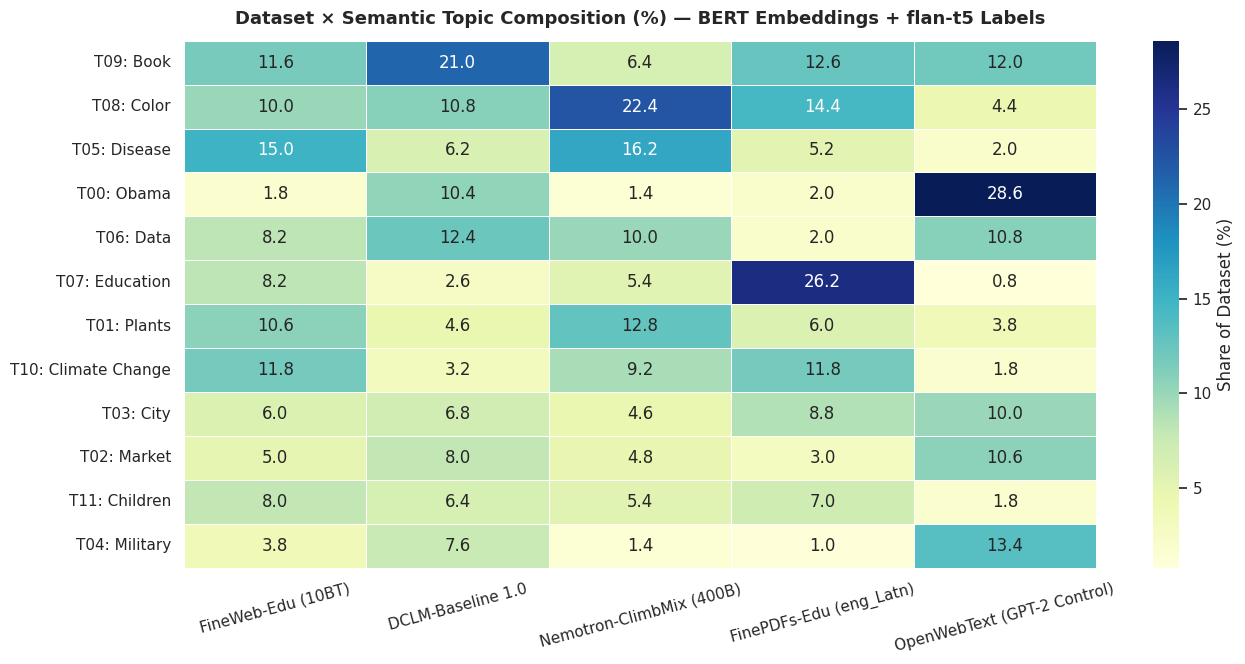

In [15]:
# === 4.4 Full-Width Dataset × Semantic Topic Composition Heatmap ===
# Ordered top-to-bottom by overall topic prevalence so dominant themes stand out cleanly.

ordered_topics = topic_catalog_df["Topic"].tolist()
heat_df = topic_dist_pct[ordered_topics].T

fig, ax = plt.subplots(figsize=(13.5, 6.8))
sns.heatmap(
    heat_df,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.6,
    linecolor="white",
    ax=ax,
    cbar_kws={"label": "Share of Dataset (%)"},
)
ax.set_title(
    "Dataset × Semantic Topic Composition (%) — BERT Embeddings + flan-t5 Labels",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=15)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_bert_topic_modeling.png", dpi=150, bbox_inches="tight")
plt.show()


### Five Datasets, Five Distinct Personalities

Scan across that heatmap and each corpus practically tells you its life story:

* **`OpenWebText` (GPT-2's world) is hooked on politics & breaking news:** A massive **42.0%** lands in just two buckets—US politics/elections/sports (`T00: 28.6%`) and military/government (`T04: 13.4%`). Meanwhile, biology, medicine, and climate science combined (`T05 + T01 + T10`) scrape together only **7.6%**. That explains in one glance why GPT-2 XL sounds slick on news prose yet leaves plenty of room for a smaller modern model on science and structured reasoning.
* **`FineWeb-Edu` is the well-rounded honor student (`3.437` bits topic entropy — highest of all five):** It puts **37.4%** into science, health, and environment (`T05: 15.0%`, `T10: 11.8%`, `T01: 10.6%`), while keeping healthy servings of general books/prose (`T09: 11.6%`), practical explanations (`T08: 10.0%`), tech (`T06: 8.2%`), and psychology/family (`T11: 8.0%`)—with barely any political chatter (`5.6%`).
* **`DCLM-Baseline 1.0` (`3.373` bits) is the fluent storyteller & tech heavyweight:** **21.0%** narrative/books/culture (`T09`) and **12.4%** technology (`T06`), plus **18.0%** real-world news (`T00 + T04`) and **8.0%** business/finance (`T02`). Less textbook science (`14.0%`), much richer general prose and everyday reasoning.
* **`Nemotron-ClimbMix` (`3.233` bits) goes all-in on science & how-to Q&A:** A huge **60.6%** of its documents sit inside core science/health/climate (`38.2%`) and practical Q&A/how-to explanations (`T08: 22.4%`—spot `"answer"` right inside T08's top keywords). The trade-off is lighter narrative fiction (`T09: 6.4%`).
* **`FinePDFs-Edu` (`3.136` bits) is a school-binder specialist:** Over a quarter (**26.2%**) is curriculum/classroom/administrative PDFs (`T07`), while technology barely registers at **2.0%** (`T06`). Useful as a long-context supplement, far too lopsided to serve as our only dataset.


---
## 5. Side-by-Side Summary & Published Scaling Evidence

No arbitrary composite weights, and zero peeking at held-out test sets—just every corpus-level measurement laid out cleanly side by side and exported for `README.md`.


In [16]:
# === 5.1 Build Unweighted Side-by-Side Corpus Summary Table ===
# Combines length profile, formatting cleanliness, and Shannon topic entropy
# (higher bits = more evenly distributed across the 12 discovered semantic themes).

eda_lookup = eda_df.set_index("Dataset")
summary_rows: list[dict[str, Any]] = []

for key in ds_keys:
    label = ds_labels[key]
    recs = candidate_slices[key]
    total_tok = sum(r["n_tokens"] for r in recs)

    # Shannon entropy H = -sum(p * log2(p)) over non-zero topic probabilities (max = log2(12) ≈ 3.585 bits)
    t_probs = topic_dist_pct.loc[label].to_numpy(dtype=np.float64) / 100.0
    t_probs = t_probs[t_probs > 0.0]
    topic_entropy = float(-np.sum(t_probs * np.log2(t_probs))) if len(t_probs) else 0.0

    summary_rows.append({
        "Dataset": label,
        "License": CANDIDATE_DATASETS[key].license,
        "Docs": len(recs),
        "Tokens": total_tok,
        "Median Tok/Doc": float(eda_lookup.loc[label, "Median Tok/Doc"]),
        "Mean Tok/Doc": round(total_tok / max(len(recs), 1), 1),
        "P99 Tok/Doc": float(eda_lookup.loc[label, "P99 Tok/Doc"]),
        "Newlines / 1k": float(eda_lookup.loc[label, "Newlines / 1k Chars"]),
        "Topic Entropy (bits)": round(topic_entropy, 3),
    })

summary_df = pd.DataFrame(summary_rows)

print("=== Kestrel Dataset Audit — Side-by-Side Corpus Summary ===")
styled = (
    summary_df.style
    .background_gradient(subset=["Topic Entropy (bits)"], cmap="Greens")
    .format({
        "Docs": "{:,}",
        "Tokens": "{:,}",
        "Median Tok/Doc": "{:,.1f}",
        "Mean Tok/Doc": "{:,.1f}",
        "P99 Tok/Doc": "{:,.1f}",
        "Newlines / 1k": "{:.2f}",
        "Topic Entropy (bits)": "{:.3f}",
    })
)
display(styled)


=== Kestrel Dataset Audit — Side-by-Side Corpus Summary ===


,Dataset,License,Docs,Tokens,Median Tok/Doc,Mean Tok/Doc,P99 Tok/Doc,Newlines / 1k,Topic Entropy (bits)
0,FineWeb-Edu (10BT),ODC-By v1.0,"3,319","3,501,102",644.0,"1,054.9","7,930.6",4.53,3.437
1,DCLM-Baseline 1.0,CC-BY-4.0,"2,734","3,500,699",674.5,"1,280.4","12,961.3",12.26,3.373
2,Nemotron-ClimbMix (400B),CC-BY-NC-4.0 (upstream NVIDIA; MIT mirror),"5,000","3,160,216",541.0,632.0,"3,871.3",7.57,3.233
3,FinePDFs-Edu (eng_Latn),ODC-By v1.0,"1,080","3,500,022","1,356.0","3,240.8","30,095.2",17.43,3.136
4,OpenWebText (GPT-2 Control),Public Domain / CC0,"3,160","3,500,186",724.5,"1,107.7","6,965.8",8.87,3.049


In [17]:
# === 5.2 Export Machine-Readable Audit Artifacts (CSV & JSON) ===
# Persists raw summary tables and run configuration for README / documentation tracking.

summary_csv = SAMPLES_DIR / "comparison_summary.csv"
topics_csv = SAMPLES_DIR / "topic_distribution.csv"
audit_json = SAMPLES_DIR / "audit_summary.json"

summary_df.to_csv(summary_csv, index=False)
topic_catalog_df.to_csv(topics_csv, index=False)

audit_payload = {
    "config": {
        "target_tokens": TARGET_TOKENS,
        "max_docs": MAX_DOCS,
        "random_sample": RANDOM_SAMPLE,
        "num_shards": NUM_SHARDS_TO_SAMPLE,
        "bert_model": BERT_EMBED_MODEL,
        "topic_namer": TOPIC_NAMER_MODEL,
        "n_topics": N_TOPICS,
    },
    "summary": summary_df.to_dict(orient="records"),
}
audit_json.write_text(json.dumps(audit_payload, indent=2), encoding="utf-8")

print(f"Saved comparison CSV     : {summary_csv}")
print(f"Saved topic distribution : {topics_csv}")
print(f"Saved audit summary JSON : {audit_json}")
print(f"Saved figures under      : {FIGURES_DIR}")


Saved comparison CSV     : /kaggle/working/samples/comparison_summary.csv
Saved topic distribution : /kaggle/working/samples/topic_distribution.csv
Saved audit summary JSON : /kaggle/working/samples/audit_summary.json
Saved figures under      : /kaggle/working/samples/figures


### Connecting Our Audit to Published Scaling Curves

Reading the data and mapping BERT topics tells us *what's inside each corpus* and catches red flags early (`FinePDFs-Edu`'s SEO spam and 26% school-PDF skew; `OpenWebText`'s 42% news/politics skew). To know how efficiently each remaining finalist actually trains a model—without cheating by peeking at our own test sets—we pair our audit with controlled pretraining results from the literature:

* **CLIMB paper (1B, 32B–400B tokens):** **`Nemotron-ClimbMix` (`52.43%`)** > **`DCLM-Baseline` (`~50.2%`)** > **`FineWeb-Edu` (`~49.4%`)**.
* **DCLM paper (7B, 140B & 280B tokens):** **`DCLM-Baseline`** decisively outperforms **`FineWeb-Edu`** at both token budgets—reaching **`48.9` vs. `41.9` CORE** (+7.0), **`50.8` vs. `37.3` MMLU** (+13.5), and **`31.8` vs. `24.5` EXTENDED** (+7.3) at 280B tokens.
* **FineWeb-Edu paper (1.8B, 350B tokens):** **`FineWeb-Edu`** decisively outperforms older 2023–2024 web dumps (`FineWeb`, `C4`, `Dolma`, `RefinedWeb`, `SlimPajama`, `The Pile`, `RedPajama2`)—all of which predated `DCLM-Baseline` and `ClimbMix`.

### 🏁 Narrowed Down to Three Finalists

Sticking to **one dataset for the entire training run** leaves three crystal-clear finalists (ruling out `OpenWebText` as our legacy control and `FinePDFs-Edu` as too narrow/noisy to stand alone):

1. **`Nemotron-ClimbMix (400B)`** — Peak sub-1B reasoning efficiency *(upstream `CC-BY-NC-4.0` non-commercial terms)*. Purpose-built via CLIMB clustering, packed with science + practical Q&A (`60.6%`), and #1 on CLIMB's 1B scaling curves. Expect shorter docs (`632` tok/doc) and occasional raw HTML tags.
2. **`DCLM-Baseline 1.0`** — Strongest commercially permissive all-rounder (`CC-BY-4.0`). Proven to beat `FineWeb-Edu` by **+7.0 CORE** and **+13.5 MMLU** at 280B tokens, with fluent long-form web prose (`1,280` tok/doc) and broad coverage (`3.373` bits entropy).
3. **`FineWeb-Edu`** — Cleanest educational permissive corpus (`ODC-By v1.0`). Highest topic breadth (`3.437` bits) and cleanest paragraph formatting (`4.53` newlines/1k chars), though trailing `DCLM-Baseline` and `ClimbMix` on published general scaling benchmarks.

Next stop: lock in Kestrel's final single-dataset choice and document the full justification in `README.md`.
